# 🧩 Chapter 1 · Cutting the Story
## RAG Step 1 — Document Loading & Chunking

> **Mission briefing.** Our library has one long article. A language model can only read a limited amount of text at once, and a search engine works best on focused pieces. Before anything can be found or answered, the article has to be **loaded** from a file and **cut into chunks**, without slicing through the middle of an idea.

**Your quest log**

| Quest | What happens | What you'll understand |
|---|---|---|
| 🗃️ **1 · Create & load** | Write a sample article to `.txt` and `.pdf`, then read both back | How documents enter a RAG pipeline |
| ✂️ **2 · Cut five ways** | Fixed-size, character, recursive, sentence and token chunking | The trade-off behind each strategy |
| 🔬 **3 · X-ray** | Every chunk is painted over the original text | Where cuts land, and where chunks overlap |
| 🏁 **4 · Compare & check** | Scoreboard, chart and a quick check | Which strategy to reach for, and why |

### ⚙️ Setup
Install the libraries. The first run takes a minute.

In [ ]:
!pip install -q langchain langchain-text-splitters tiktoken pypdf fpdf2

### 🎛️ Lab kit
This cell only defines small display helpers: the pipeline tracker, stat cards, and the **X-ray** that paints chunks over the text. The chunking logic itself is written out in full in each strategy below.

In [2]:
# 🎛️ Lab kit · small display helpers for this chapter
import html
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, HTML

STEPS = ["Load & Chunk", "Store", "Retrieve", "Generate"]
PALETTE = ["#fde68a", "#a7f3d0", "#bfdbfe", "#fbcfe8", "#ddd6fe", "#fed7aa", "#bae6fd", "#d9f99d"]
OVERLAP_STYLE = ("background:repeating-linear-gradient(45deg,#fde68a 0 4px,#fca5a5 4px 8px);"
                 "box-shadow:inset 0 -2px #dc2626")


def pipeline_tracker(current):
    """Show the four RAG steps and highlight the one we are on."""
    pills = []
    for i, name in enumerate(STEPS, start=1):
        if i < current:
            style, tag = "background:#d1fae5;color:#065f46", " ✓"
        elif i == current:
            style, tag = ("background:#4f46e5;color:#ffffff;"
                          "box-shadow:0 4px 12px rgba(79,70,229,.35)"), "  ← you are here"
        else:
            style, tag = "background:#f1f5f9;color:#64748b", ""
        pills.append(
            f'<div style="flex:1;min-width:150px;padding:10px 14px;border-radius:12px;{style}">'
            f'<div style="font-size:11px;letter-spacing:.08em;opacity:.8">STEP {i}</div>'
            f'<div style="font-weight:600">{name}{tag}</div></div>'
        )
    return ('<div style="display:flex;gap:10px;flex-wrap:wrap;font-family:system-ui,sans-serif">'
            + "".join(pills) + "</div>")


def stat_cards(stats):
    """Turn a {label: value} dict into a row of big-number cards."""
    cards = []
    for label, value in stats.items():
        shown = f"{value:,}" if isinstance(value, int) else str(value)
        cards.append(
            '<div style="flex:1;min-width:130px;background:#f8fafc;border:1px solid #e2e8f0;'
            'border-radius:12px;padding:12px;text-align:center">'
            f'<div style="font-size:22px;font-weight:700;color:#4f46e5">{html.escape(shown)}</div>'
            f'<div style="font-size:12px;color:#64748b">{html.escape(label)}</div></div>'
        )
    return '<div style="display:flex;gap:10px;flex-wrap:wrap">' + "".join(cards) + "</div>"


def preview_panel(text, caption):
    return (
        '<div style="border-left:4px solid #6366f1;background:#f8fafc;padding:12px 16px;border-radius:8px">'
        f'<div style="font-size:12px;color:#64748b;margin-bottom:6px">{html.escape(caption)}</div>'
        '<pre style="white-space:pre-wrap;margin:0;font-family:Georgia,serif;font-size:14px">'
        f'{html.escape(text)}</pre></div>'
    )


def _collapse_ws(text):
    """Squash each run of whitespace into one space, remembering where every kept character came from."""
    out, origin, prev_space = [], [], True  # starting True drops leading whitespace
    for i, ch in enumerate(text):
        if ch.isspace():
            if not prev_space:
                out.append(" ")
                origin.append(i)
            prev_space = True
        else:
            out.append(ch)
            origin.append(i)
            prev_space = False
    return "".join(out), origin


def locate_chunks(text, chunks):
    """Find where each chunk sits inside the original text, ignoring whitespace differences."""
    flat, origin = _collapse_ws(text)
    spans, cursor = [], 0
    for chunk in chunks:
        needle = _collapse_ws(chunk)[0].strip()
        pos = flat.find(needle, cursor) if needle else -1
        if pos == -1:
            spans.append(None)
            continue
        spans.append((origin[pos], origin[pos + len(needle) - 1] + 1))
        cursor = pos + 1  # chunks come in order, but the next one may start inside this one
    return spans


def xray(text, chunks, title):
    """Paint every chunk over the original text. Text covered by two or more chunks gets a red-striped highlight."""
    spans = locate_chunks(text, chunks)
    cuts = sorted({0, len(text)} | {p for s in spans if s for p in s})
    pieces, overlap_chars = [], 0
    for a, b in zip(cuts, cuts[1:]):
        owners = [k for k, s in enumerate(spans) if s and s[0] <= a and b <= s[1]]
        fragment = html.escape(text[a:b])
        if not owners:
            pieces.append(f'<span style="color:#cbd5e1">{fragment}</span>')
        elif len(owners) == 1:
            color = PALETTE[owners[0] % len(PALETTE)]
            pieces.append(f'<span title="chunk {owners[0]}" style="background:{color};border-radius:4px">{fragment}</span>')
        else:
            overlap_chars += b - a
            who = ", ".join(str(k) for k in owners)
            pieces.append(f'<span title="overlap: chunks {who}" style="{OVERLAP_STYLE};border-radius:4px">{fragment}</span>')
    body = "".join(pieces)
    legend = "".join(
        f'<span style="display:inline-block;margin:2px 4px 2px 0;padding:2px 9px;border-radius:999px;'
        f'background:{PALETTE[k % len(PALETTE)]};font-size:12px">#{k} · {len(c)} chars</span>'
        for k, c in enumerate(chunks)
    )
    missing = sum(1 for s in spans if s is None)
    note = (f'<div style="color:#b91c1c;font-size:12px;margin-top:6px">⚠ {missing} chunk(s) could not be located</div>'
            if missing else "")
    return (
        '<div style="font-family:system-ui,sans-serif;margin:18px 0">'
        f'<div style="font-weight:700;font-size:16px">{html.escape(title)}</div>'
        f'<div style="color:#64748b;font-size:13px;margin-bottom:8px">{len(chunks)} chunks · '
        f'{overlap_chars} characters covered by two or more chunks</div>'
        f'<div style="margin-bottom:8px">{legend}</div>{note}'
        '<div style="white-space:pre-wrap;font-family:Georgia,serif;line-height:1.7;font-size:14px;'
        'background:#ffffff;border:1px solid #e2e8f0;border-radius:10px;padding:14px;max-height:380px;overflow:auto">'
        f'{body}</div></div>'
    )


display(HTML(pipeline_tracker(1)))

## 🗃️ Quest 1 · Create the document
Our librarian has a short article about AI. We'll write it to a file, then read it back, the same way a real pipeline loads documents.

In [3]:
import os

os.makedirs("docs", exist_ok=True)

article_text = """Artificial Intelligence: An Overview

Artificial Intelligence, or AI, is the field of computer science focused on building systems
that can perform tasks which normally require human intelligence. These tasks include
understanding language, recognizing images, making decisions, and learning from experience.

Machine Learning is a subset of AI where systems learn patterns from data instead of following
hardcoded rules. Instead of programming every decision by hand, we feed the system many examples,
and it learns the underlying pattern on its own. This approach powers everything from spam filters
to recommendation systems.

Deep Learning takes Machine Learning further by using neural networks with many layers. These
layered networks can automatically discover complex patterns in large amounts of data, such as
recognizing faces in photos or understanding the meaning of a sentence.

Natural Language Processing, or NLP, is the branch of AI that focuses specifically on human
language. NLP powers chatbots, translation tools, and search engines. A key building block of
modern NLP is the embedding, which converts words or sentences into numeric vectors that capture
meaning.

Retrieval-Augmented Generation, or RAG, is a technique that combines a search system with a
language model. Instead of relying only on what a language model memorized during training, RAG
first retrieves relevant, up-to-date information from a document collection, then passes that
information to the model so it can generate a more accurate, grounded answer.

Vector Databases store embeddings and allow fast similarity search across millions of documents.
They are a core infrastructure piece behind modern RAG systems, chatbots, and recommendation
engines used by companies around the world today.
"""

with open("docs/sample_article.txt", "w") as f:
    f.write(article_text)

display(HTML(stat_cards({
    "characters": len(article_text),
    "words": len(article_text.split()),
    "saved to": "docs/sample_article.txt",
})))

Now load it back, the way a real pipeline would:

In [4]:
with open("docs/sample_article.txt", "r") as f:
    loaded_text = f.read()

display(HTML(preview_panel(loaded_text[:300] + " ...", "Loaded document · first 300 characters")))

### 📄 Bonus format: PDF
Most real-world documents arrive as PDFs. We'll generate one from the same text and extract the words back out, which is a very common loading step.

In [5]:
from fpdf import FPDF

pdf = FPDF()
pdf.add_page()
pdf.set_font("Times", size=12)

for line in article_text.split("\n"):
    # Using an explicit width (e.g., 190mm for A4 page with margins) instead of 0
    pdf.multi_cell(190, 8, line)

pdf.output("docs/sample_article.pdf")
print("PDF created: docs/sample_article.pdf")

PDF created: docs/sample_article.pdf


In [6]:
from pypdf import PdfReader

reader = PdfReader("docs/sample_article.pdf")

pdf_text = ""
for page in reader.pages:
    pdf_text += page.extract_text() + "\n"

display(HTML(stat_cards({"pages found": len(reader.pages), "characters extracted": len(pdf_text)})))
display(HTML(preview_panel(pdf_text[:300] + " ...", "Extracted from the PDF · first 300 characters")))

## ✂️ Quest 2 · Cut five ways

> 🔮 **Predict before you run.** Which strategy will produce the **most** chunks? Which will produce the **fewest**? Commit to an answer now. Quest 3 reveals the truth.

After each strategy you'll get an **X-ray**: the whole article with every chunk painted in its own color. Where two chunks share characters, the text gets a red-striped highlight. Hover over any colored span to see which chunk it belongs to.

### Strategy 1 · Fixed-size (from scratch)
*Count characters, cut every N, then step back by an overlap. Simple, but blind to meaning.*

In [7]:
def fixed_size_chunking(text, chunk_size=300, overlap=50):
    chunks = []
    start = 0
    while start < len(text):
        end = start + chunk_size
        chunks.append(text[start:end])
        start += chunk_size - overlap
    return chunks


fixed_chunks = fixed_size_chunking(loaded_text, chunk_size=300, overlap=50)
display(HTML(xray(loaded_text, fixed_chunks, "Strategy 1 · Fixed-size (from scratch)")))

### Strategy 2 · `CharacterTextSplitter`
*Split on paragraph breaks (`\n\n`), then pack paragraphs into chunks of up to 300 characters. A paragraph longer than the limit can't be split here, so some chunks overshoot. The warnings below are LangChain telling you exactly that.*

In [8]:
from langchain_text_splitters import CharacterTextSplitter

char_splitter = CharacterTextSplitter(
    separator="\n\n",
    chunk_size=300,
    chunk_overlap=50
)

char_chunks = char_splitter.split_text(loaded_text)
display(HTML(xray(loaded_text, char_chunks, "Strategy 2 · CharacterTextSplitter")))

Created a chunk of size 318, which is longer than the specified 300


Created a chunk of size 359, which is longer than the specified 300


### Strategy 3 · `RecursiveCharacterTextSplitter`
*Try the biggest natural boundary first (paragraphs), then lines, then sentences, then words. It's the go-to default in many RAG projects because it respects structure whenever it can.*

In [9]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
    separators=["\n\n", "\n", ". ", " ", ""]
)

recursive_chunks = recursive_splitter.split_text(loaded_text)
display(HTML(xray(loaded_text, recursive_chunks, "Strategy 3 · RecursiveCharacterTextSplitter")))

### Strategy 4 · Sentence-based
*Split on sentence punctuation with a regular expression, then group two sentences per chunk. Easy to read, but the regex is naive: it can't tell that the full stop in "e.g." doesn't end a sentence.*

In [10]:
import re

def sentence_chunking(text, sentences_per_chunk=2):
    # Simple sentence splitter using punctuation (no extra downloads needed)
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    sentences = [s for s in sentences if s]

    chunks = []
    for i in range(0, len(sentences), sentences_per_chunk):
        chunk = " ".join(sentences[i:i + sentences_per_chunk])
        chunks.append(chunk)
    return chunks


sentence_chunks = sentence_chunking(loaded_text, sentences_per_chunk=2)
display(HTML(xray(loaded_text, sentence_chunks, "Strategy 4 · Sentence-based (2 sentences per chunk)")))

### Strategy 5 · Token-based
*Language models count **tokens**, not characters. We encode the text with `cl100k_base` (the tokenizer used by GPT-3.5 and GPT-4 models), then cut every 60 tokens with 10 tokens of overlap.*

In [11]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

def token_chunking(text, max_tokens=60, overlap_tokens=10):
    tokens = encoding.encode(text)
    chunks = []
    start = 0
    while start < len(tokens):
        end = start + max_tokens
        chunk_tokens = tokens[start:end]
        chunks.append(encoding.decode(chunk_tokens))
        start += max_tokens - overlap_tokens
    return chunks


token_chunks = token_chunking(loaded_text, max_tokens=60, overlap_tokens=10)
display(HTML(xray(loaded_text, token_chunks, "Strategy 5 · Token-based (60 tokens, 10 overlap)")))
print("Tokens per chunk:", [len(encoding.encode(c)) for c in token_chunks])

Tokens per chunk: [60, 60, 60, 60, 60, 60, 35]


## 🔬 Quest 3 · The scoreboard
Did your prediction hold up? The table ranks the five strategies, and the chart shows the same numbers visually.

In [12]:
comparison = pd.DataFrame({
    "Strategy": [
        "Fixed-size (scratch)",
        "CharacterTextSplitter",
        "RecursiveCharacterTextSplitter",
        "Sentence-based",
        "Token-based"
    ],
    "Number of Chunks": [
        len(fixed_chunks),
        len(char_chunks),
        len(recursive_chunks),
        len(sentence_chunks),
        len(token_chunks)
    ],
    "Avg Chunk Length (chars)": [
        round(sum(len(c) for c in fixed_chunks) / len(fixed_chunks), 1),
        round(sum(len(c) for c in char_chunks) / len(char_chunks), 1),
        round(sum(len(c) for c in recursive_chunks) / len(recursive_chunks), 1),
        round(sum(len(c) for c in sentence_chunks) / len(sentence_chunks), 1),
        round(sum(len(c) for c in token_chunks) / len(token_chunks), 1)
    ]
})

(comparison.style
    .background_gradient(subset=["Number of Chunks"], cmap="Blues")
    .background_gradient(subset=["Avg Chunk Length (chars)"], cmap="Greens")
    .format({"Avg Chunk Length (chars)": "{:.1f}"})
    .hide(axis="index"))

Strategy,Number of Chunks,Avg Chunk Length (chars)
Fixed-size (scratch),8,265.2
CharacterTextSplitter,7,253.3
RecursiveCharacterTextSplitter,9,196.8
Sentence-based,7,253.4
Token-based,7,305.0


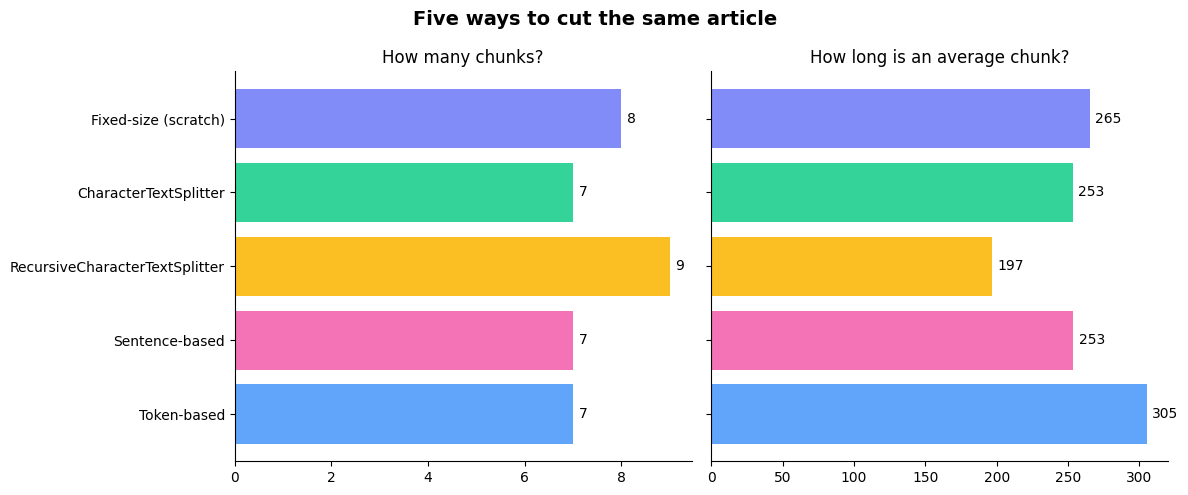

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
bar_colors = ["#818cf8", "#34d399", "#fbbf24", "#f472b6", "#60a5fa"]

bars1 = ax1.barh(comparison["Strategy"], comparison["Number of Chunks"], color=bar_colors)
ax1.bar_label(bars1, padding=4)
ax1.set_title("How many chunks?")
ax1.invert_yaxis()

bars2 = ax2.barh(comparison["Strategy"], comparison["Avg Chunk Length (chars)"], color=bar_colors)
ax2.bar_label(bars2, fmt="%.0f", padding=4)
ax2.set_title("How long is an average chunk?")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Five ways to cut the same article", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 🏆 Verdict
- **Fixed-size** cut blindly: its second chunk begins at "ng images", and the first ends at "learning from exp", so the word *experience* is split across the seam.
- **Recursive** produced the most chunks (9) and the shortest average, because it had to break the long Machine Learning paragraph and left a 26-character fragment, "to recommendation systems.", as its own chunk.
- **Token-based** produced the longest average chunks. It measures by tokens instead of characters, which is exactly what you want when a model has a strict token limit.

Look closely at the **Recursive** and **CharacterTextSplitter** X-rays: they show **zero** repeated characters. Overlap is counted in whole pieces, and these paragraphs are longer than the 50-character overlap, so nothing gets repeated. The X-ray makes that visible, which is exactly why it's worth looking at instead of just counting chunks.

No strategy is "best" in general. The right choice depends on your documents and your model.

## 🧭 Quest 4 · Quick check
Try to answer each question before you expand the answer.

<details><summary><b>Q1. Why does fixed-size chunking split words like "experience"?</b></summary>
It only counts characters. It has no idea where words, sentences or paragraphs begin and end, so the cut lands wherever the count runs out.
</details>

<details><summary><b>Q2. What does chunk overlap buy us?</b></summary>
A sentence that falls on a boundary still appears whole in at least one chunk, so no context is lost at the seams. The price is some duplicated text and extra storage.
</details>

<details><summary><b>Q3. When would you choose token-based chunking?</b></summary>
When you must respect an exact token budget, such as the input limit of a specific model. Models read tokens, so token-sized chunks fit precisely.
</details>

## 🧰 Field notes · which strategy when?

| Strategy | Splits on | Reach for it when… | Watch out for… |
|---|---|---|---|
| Fixed-size | A character count | You need a quick baseline | Cuts mid-word and mid-sentence |
| `CharacterTextSplitter` | One separator (`\n\n`) | Text is neatly organized into paragraphs | Chunks can overshoot when paragraphs are long |
| `RecursiveCharacterTextSplitter` | Paragraphs → lines → sentences → words | You want a sensible general-purpose default | Chunk sizes vary |
| Sentence-based | Sentence punctuation | Clean prose, where sentences are the unit of meaning | A naive regex misreads abbreviations |
| Token-based | Model tokens | You must fit an exact model token limit | Can split words; chunks are less readable |

**Chapter takeaway:** a good chunker keeps related sentences together and respects your model's size limit. Test two or three strategies on your own documents, inspect them with an X-ray, and only then commit.

**Next chapter →** Chapter 2 stores these chunks in ChromaDB, where each one gets a label, some tags and a meaning fingerprint.